# 😴 Sleep Quality Prediction using Logistic Regression

**Goal:** Predict whether a person's sleep quality is **Good** or **Poor** from lifestyle habits.

**Dataset:** `sleep_quality_data.csv` (445 rows) with columns `id, gender, age, screen_time, caffeine_intake, exercise_hours, sleep_quality`. It intentionally contains **missing values** and **duplicate rows**.

**Workflow**
1. Import libraries & load data
2. Data inspection
3. Data cleaning (duplicates, nulls)
4. Exploratory Data Analysis (histograms, bar charts, boxplots, heatmap)
5. Encoding categorical data
6. Train / test split
7. Model training (Logistic Regression)
8. Evaluation (accuracy, confusion matrix, classification report, ROC)
9. Feature importance, save model, sample prediction

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42

## 2. Load & Inspect the Data

In [2]:
df = pd.read_csv("sleep_quality_data.csv")
print("Shape:", df.shape)
df.head(10)

Shape: (445, 7)


,id,gender,age,screen_time,caffeine_intake,exercise_hours,sleep_quality
0,230,Male,18.0,11.6,2.0,1.25,Poor
1,28,Male,34.0,4.3,3.0,0.57,Poor
2,245,Female,NaN,9.1,2.0,0.33,Poor
3,158,Female,NaN,1.7,3.0,0.79,Poor
4,145,Male,36.0,7.8,4.0,0.63,Poor
5,89,Male,27.0,6.9,3.0,1.47,Good
6,308,Female,36.0,4.8,4.0,0.16,Poor
7,160,Female,23.0,7.3,4.0,0.55,Poor
8,67,Female,33.0,3.4,2.0,2.32,Good
9,125,Male,32.0,6.5,5.0,0.81,Poor


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 445 entries, 0 to 444
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               445 non-null    int64  
 1   gender           437 non-null    object 
 2   age              431 non-null    float64
 3   screen_time      429 non-null    float64
 4   caffeine_intake  433 non-null    float64
 5   exercise_hours   431 non-null    float64
 6   sleep_quality    445 non-null    object 
dtypes: float64(4), int64(1), object(2)
memory usage: 24.5+ KB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,445.0,NaN,NaN,NaN,211.964045,121.674831,1.0,106.0,214.0,315.0,420.0
gender,437,3,Female,214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,431.0,NaN,NaN,NaN,29.918794,8.26792,18.0,23.0,30.0,35.5,53.0
screen_time,429.0,NaN,NaN,NaN,5.581119,2.39957,0.5,3.9,5.6,7.0,12.0
caffeine_intake,433.0,NaN,NaN,NaN,2.618938,1.575364,0.0,2.0,2.0,4.0,8.0
exercise_hours,431.0,NaN,NaN,NaN,1.020766,0.673807,0.02,0.49,0.89,1.415,3.0
sleep_quality,445,2,Poor,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
id                  0
gender              8
age                14
screen_time        16
caffeine_intake    12
exercise_hours     14
sleep_quality       0
dtype: int64

Total missing values: 64
Duplicate rows: 25


**Observation:** the data has missing values in `gender`, `age`, `screen_time`, `caffeine_intake` and `exercise_hours`, plus fully duplicated rows. Both must be handled before modelling.

## 3. Data Cleaning

### 3.1 Remove duplicate rows

In [6]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before} | Rows after: {len(df)} | Removed: {before - len(df)}")
print("Duplicates remaining:", df.duplicated().sum())

Rows before: 445 | Rows after: 420 | Removed: 25
Duplicates remaining: 0


### 3.2 Drop the `id` column
`id` is only an identifier and carries no predictive information, so we remove it.

In [7]:
df = df.drop(columns=["id"])
df.columns.tolist()

['gender',
 'age',
 'screen_time',
 'caffeine_intake',
 'exercise_hours',
 'sleep_quality']

### 3.3 Handle missing values
- **Numeric columns** (`age`, `screen_time`, `caffeine_intake`, `exercise_hours`): fill with the **median** (robust to outliers).
- **Categorical column** (`gender`): fill with the **mode** (most frequent value).
- The target `sleep_quality` has no nulls. If it did, we would drop those rows.

*(Alternative: `df.dropna()` removes every row with a null. With ~13% of rows affected, filling keeps more data.)*

In [8]:
print("Nulls BEFORE filling:\n", df.isnull().sum(), "\n")

num_cols = ["age", "screen_time", "caffeine_intake", "exercise_hours"]
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

df["gender"] = df["gender"].fillna(df["gender"].mode()[0])

# Drop rows with a missing target (none here, but good practice)
df = df.dropna(subset=["sleep_quality"])

print("Nulls AFTER filling:\n", df.isnull().sum())

Nulls BEFORE filling:
 gender              8
age                12
screen_time        15
caffeine_intake    12
exercise_hours     14
sleep_quality       0
dtype: int64 

Nulls AFTER filling:
 gender             0
age                0
screen_time        0
caffeine_intake    0
exercise_hours     0
sleep_quality      0
dtype: int64


### 3.4 Fix data types

In [9]:
df["age"] = df["age"].astype(int)
df["caffeine_intake"] = df["caffeine_intake"].astype(int)
print(df.dtypes)
print("\nClean dataset shape:", df.shape)
df.head()

gender              object
age                  int32
screen_time        float64
caffeine_intake      int32
exercise_hours     float64
sleep_quality       object
dtype: object

Clean dataset shape: (420, 6)


,gender,age,screen_time,caffeine_intake,exercise_hours,sleep_quality
0,Male,18,11.6,2,1.25,Poor
1,Male,34,4.3,3,0.57,Poor
2,Female,29,9.1,2,0.33,Poor
3,Female,29,1.7,3,0.79,Poor
4,Male,36,7.8,4,0.63,Poor


## 4. Exploratory Data Analysis (EDA)

### 4.1 Summary statistics

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,420.0,29.797619,8.167664,18.00,23.0000,29.00,35.0000,53.0
screen_time,420.0,5.545238,2.363798,0.50,4.0000,5.60,7.0000,12.0
caffeine_intake,420.0,2.590476,1.529005,0.00,2.0000,2.00,3.2500,8.0
exercise_hours,420.0,1.010048,0.657632,0.02,0.5175,0.89,1.3925,3.0


### 4.2 Target distribution (bar chart)

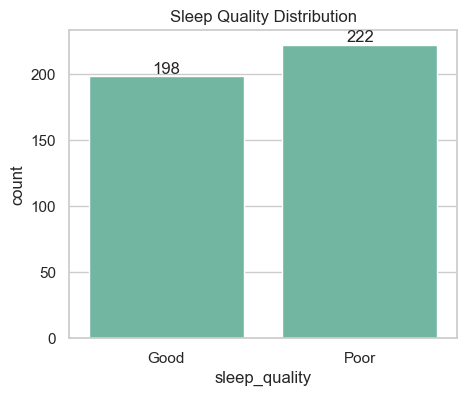

sleep_quality
Poor    0.529
Good    0.471
Name: proportion, dtype: float64


In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="sleep_quality", order=["Good", "Poor"], ax=ax)
for c in ax.containers:
    ax.bar_label(c)
ax.set_title("Sleep Quality Distribution")
plt.show()
print(df["sleep_quality"].value_counts(normalize=True).round(3))

### 4.3 Histograms of numeric features

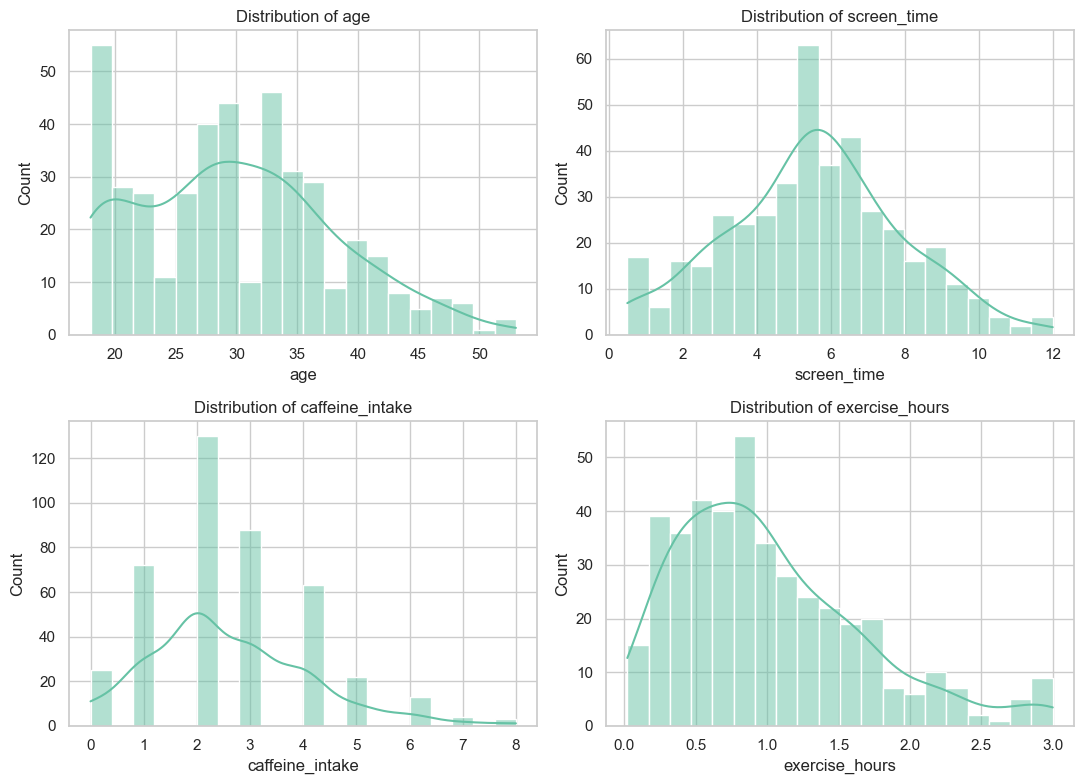

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, bins=20, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

### 4.4 Histograms split by sleep quality

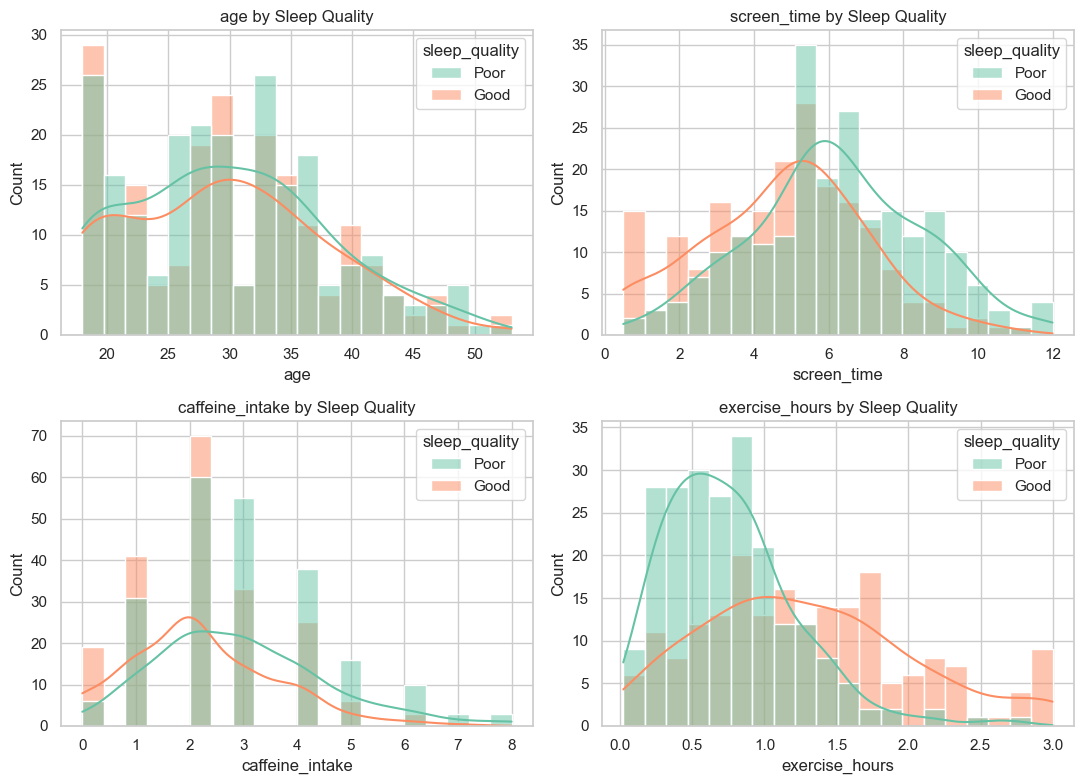

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="sleep_quality", kde=True, bins=20, ax=ax)
    ax.set_title(f"{col} by Sleep Quality")
plt.tight_layout()
plt.show()

### 4.5 Bar charts: gender vs. sleep quality & average habits per class

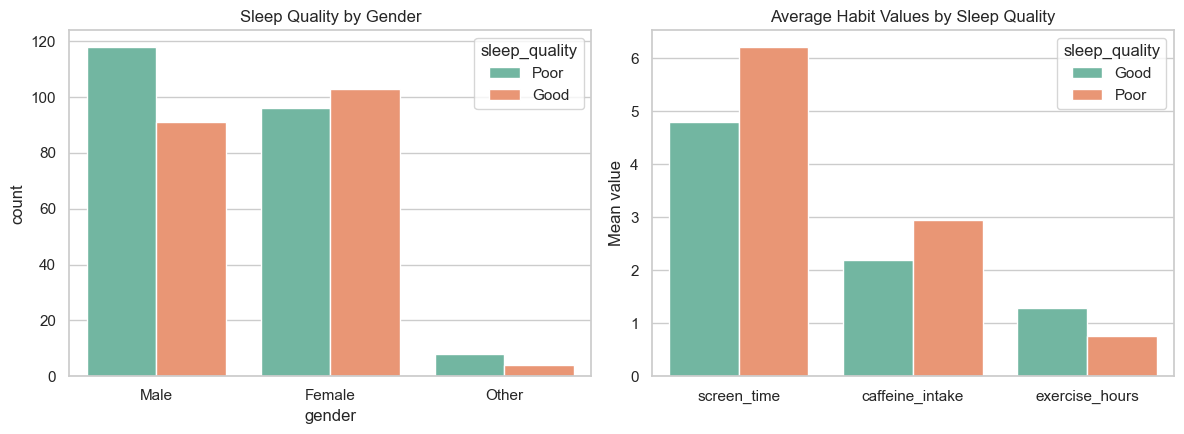

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(data=df, x="gender", hue="sleep_quality", ax=axes[0])
axes[0].set_title("Sleep Quality by Gender")

means = df.groupby("sleep_quality")[["screen_time", "caffeine_intake", "exercise_hours"]].mean().reset_index()
means.melt(id_vars="sleep_quality").pipe(
    lambda d: sns.barplot(data=d, x="variable", y="value", hue="sleep_quality", ax=axes[1]))
axes[1].set_title("Average Habit Values by Sleep Quality")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean value")
plt.tight_layout()
plt.show()

### 4.6 Boxplots (spread and outliers)

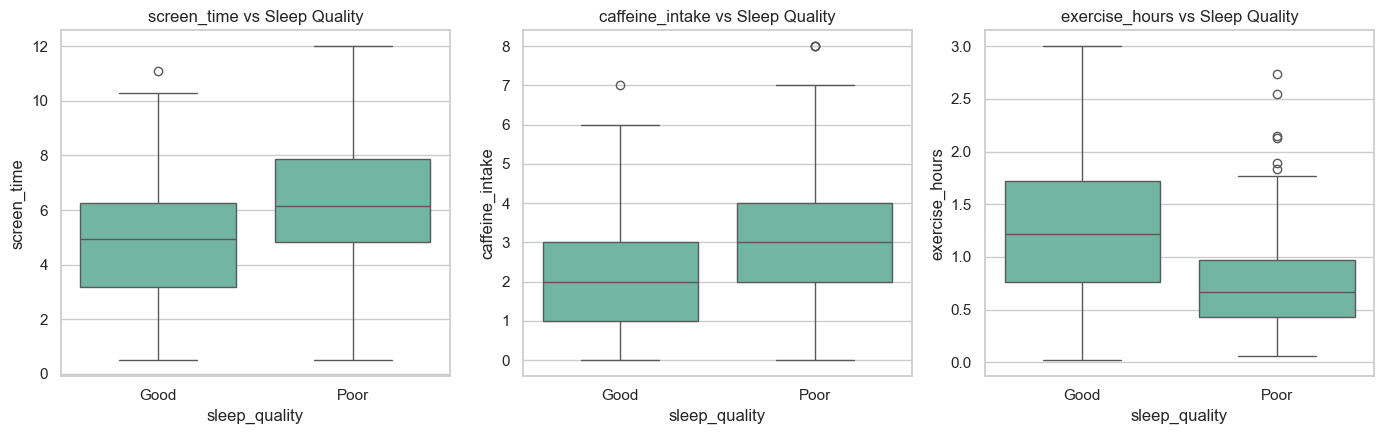

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col in zip(axes, ["screen_time", "caffeine_intake", "exercise_hours"]):
    sns.boxplot(data=df, x="sleep_quality", y=col, order=["Good", "Poor"], ax=ax)
    ax.set_title(f"{col} vs Sleep Quality")
plt.tight_layout()
plt.show()

### 4.7 Correlation heatmap

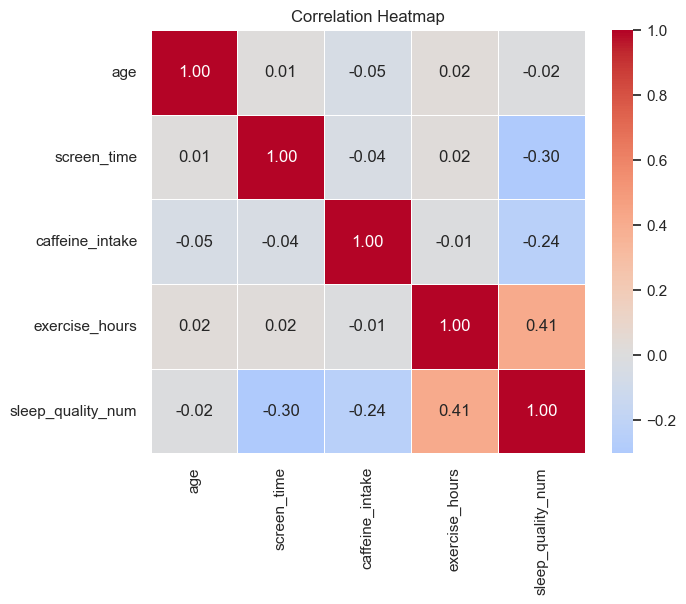

In [16]:
eda = df.copy()
eda["sleep_quality_num"] = eda["sleep_quality"].map({"Good": 1, "Poor": 0})

plt.figure(figsize=(7, 5.5))
sns.heatmap(eda[num_cols + ["sleep_quality_num"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

**EDA insights**
- `screen_time` and `caffeine_intake` are **negatively** correlated with good sleep.
- `exercise_hours` is **positively** correlated with good sleep.
- `age` has only a weak relationship with sleep quality.
- Classes are reasonably balanced, so accuracy is a fair metric.

## 5. Encode Categorical Data

- Target `sleep_quality`: **Good → 1, Poor → 0**
- Feature `gender`: one-hot encoding (`drop_first=True` avoids redundant columns)

In [17]:
df["sleep_quality"] = df["sleep_quality"].map({"Good": 1, "Poor": 0})
df_model = pd.get_dummies(df, columns=["gender"], drop_first=True, dtype=int)
df_model.head()

,age,screen_time,caffeine_intake,exercise_hours,sleep_quality,gender_Male,gender_Other
0,18,11.6,2,1.25,0,1,0
1,34,4.3,3,0.57,0,1,0
2,29,9.1,2,0.33,0,0,0
3,29,1.7,3,0.79,0,0,0
4,36,7.8,4,0.63,0,1,0


## 6. Train / Test Split

In [18]:
X = df_model.drop(columns=["sleep_quality"])
y = df_model["sleep_quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Features:", X.columns.tolist())
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class ratio:", y_train.mean().round(3), "| Test class ratio:", y_test.mean().round(3))

Features: ['age', 'screen_time', 'caffeine_intake', 'exercise_hours', 'gender_Male', 'gender_Other']
Train: (336, 6) | Test: (84, 6)
Train class ratio: 0.47 | Test class ratio: 0.476


## 7. Train the Logistic Regression Model
A `Pipeline` scales the features (fit **only on training data**, which avoids data leakage) and then fits the model.

In [19]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
print("Model trained successfully ✅")

Model trained successfully ✅


## 8. Model Evaluation

In [20]:
y_train_pred = model.predict(X_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"Training accuracy : {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Testing accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC           : {roc_auc_score(y_test, y_prob):.4f}")

Training accuracy : 0.7411
Testing accuracy  : 0.8214
ROC-AUC           : 0.8795


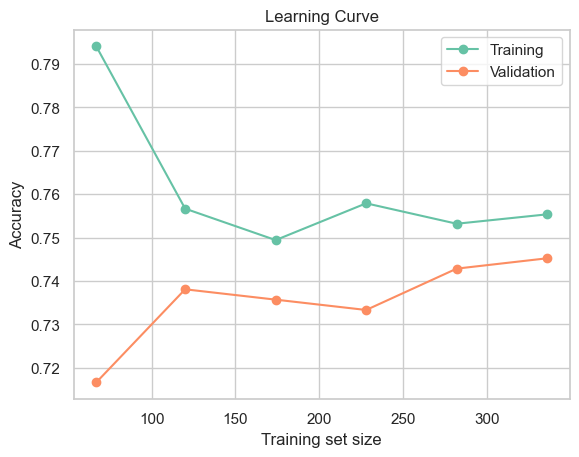

In [28]:
from sklearn.model_selection import learning_curve

sizes, train_sc, val_sc = learning_curve(model, X, y, cv=5, scoring="accuracy",
                                         train_sizes=np.linspace(0.2, 1.0, 6), random_state=42)
plt.plot(sizes, train_sc.mean(axis=1), "o-", label="Training")
plt.plot(sizes, val_sc.mean(axis=1), "o-", label="Validation")
plt.xlabel("Training set size"); plt.ylabel("Accuracy"); plt.legend()
plt.title("Learning Curve"); plt.show()

In [21]:
print(classification_report(y_test, y_pred, target_names=["Poor (0)", "Good (1)"]))

              precision    recall  f1-score   support

    Poor (0)       0.81      0.86      0.84        44
    Good (1)       0.84      0.78      0.81        40

    accuracy                           0.82        84
   macro avg       0.82      0.82      0.82        84
weighted avg       0.82      0.82      0.82        84



### 8.1 Confusion matrix

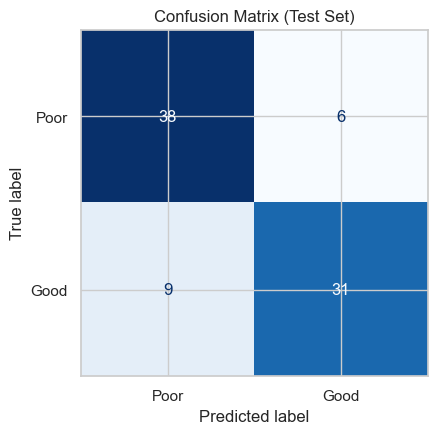

True Negatives: 38 | False Positives: 6 | False Negatives: 9 | True Positives: 31


In [22]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Poor", "Good"]).plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix (Test Set)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}")

### 8.2 ROC curve

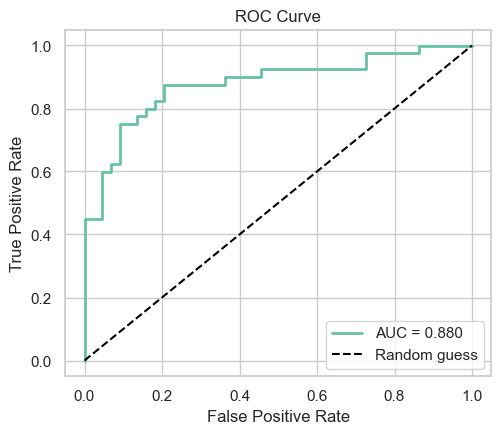

In [23]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}", lw=2)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

### 8.3 5-fold cross-validation (checks the result is stable)

In [24]:
cv_scores = cross_val_score(model, X, y, cv=5, scoring="accuracy")
print("CV accuracies:", cv_scores.round(3))
print(f"Mean CV accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

CV accuracies: [0.726 0.75  0.679 0.774 0.798]
Mean CV accuracy: 0.7452 (+/- 0.0410)


## 9. Feature Importance (model coefficients)

Coefficients are on **standardised** features, so their sizes are comparable. Positive pushes towards *Good* sleep, negative towards *Poor*.

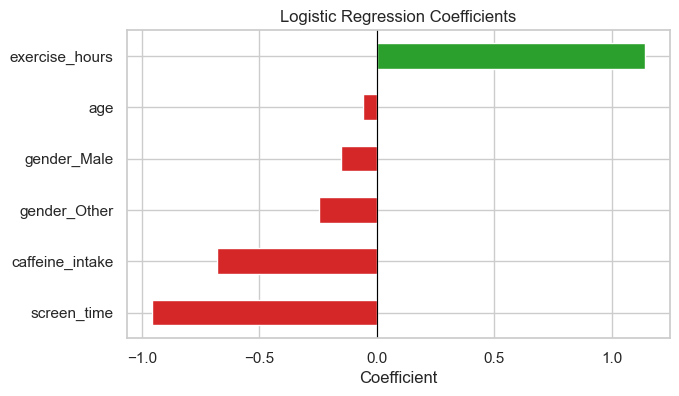

screen_time       -0.957
caffeine_intake   -0.679
gender_Other      -0.245
gender_Male       -0.152
age               -0.060
exercise_hours     1.141
dtype: float64

In [25]:
coef = pd.Series(model.named_steps["clf"].coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(7, 4))
colors = ["#d62728" if c < 0 else "#2ca02c" for c in coef]
coef.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.show()
coef.round(3)

## 10. Save the Model (for the Streamlit app)

In [26]:
joblib.dump(model, "model.pkl")
joblib.dump(X.columns.tolist(), "feature_columns.pkl")
print("Saved model.pkl and feature_columns.pkl")

Saved model.pkl and feature_columns.pkl


## 11. Predict for a New Person

In [27]:
def predict_sleep(age, gender, screen_time, caffeine_intake, exercise_hours):
    row = pd.DataFrame([{
        "age": age, "screen_time": screen_time,
        "caffeine_intake": caffeine_intake, "exercise_hours": exercise_hours,
        "gender_Male": int(gender == "Male"), "gender_Other": int(gender == "Other"),
    }])[X.columns]
    prob_good = model.predict_proba(row)[0, 1]
    return ("Good" if prob_good >= 0.5 else "Poor"), round(float(prob_good), 3)

print(predict_sleep(25, "Female", 2.0, 1, 1.5))   # healthy habits
print(predict_sleep(35, "Male", 9.5, 6, 0.1))     # unhealthy habits

('Good', 0.958)
('Poor', 0.006)


## 12. Conclusion
- Duplicates were removed, nulls filled (median for numeric, mode for gender), and `id` dropped.
- EDA showed that **higher screen time and caffeine** are linked to **poor sleep**, while **more exercise** is linked to **good sleep**.
- The Logistic Regression model reached the accuracy shown in Section 8 on unseen test data, and cross-validation confirms it is stable.
- **Limitation:** the data is synthetic, so the results demonstrate the ML workflow rather than real-world sleep science.
- **Next steps:** try Random Forest or other models for comparison, and deploy the saved model with Streamlit.